In [8]:

import pandas as pd
import matplotlib.pyplot as plt

# Create a simple student dataset
data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Marks":       [20, 25, 40, 45, 50, 65, 70, 75, 85, 95]
}

df = pd.DataFrame(data)

# Display the dataset
print(df)


   Study_Hours  Marks
0            1     20
1            2     25
2            3     40
3            4     45
4            5     50
5            6     65
6            7     70
7            8     75
8            9     85
9           10     95


In [9]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Separate input (X) and output (y)
X = df[["Study_Hours"]]
y = df["Marks"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [10]:

from sklearn.metrics import mean_absolute_error, r2_score

# Predict marks for the test data
y_pred = model.predict(X_test)

# Compare actual and predicted marks
results = pd.DataFrame({
    "Study_Hours": X_test["Study_Hours"].values,
    "Actual_Marks": y_test.values,
    "Predicted_Marks": y_pred.round(2)
})

print(results)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("\nMean Absolute Error (MAE):", round(mae, 2))
print("R2 Score:", round(r2, 2))


   Study_Hours  Actual_Marks  Predicted_Marks
0            9            85            85.86
1            2            25            29.14

Mean Absolute Error (MAE): 2.5
R2 Score: 0.99


In [11]:

from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree model
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)

# Train the model
tree_model.fit(X_train, y_train)

# Predict marks
tree_pred = tree_model.predict(X_test)

print("Decision Tree model trained successfully!")
print("\nPredicted marks:", tree_pred.round(2))


Decision Tree model trained successfully!

Predicted marks: [72.5 20. ]


In [12]:

from sklearn.metrics import mean_absolute_error, r2_score

# Evaluate both models
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree Regression"],
    "MAE": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, tree_pred)
    ],
    "R2_Score": [
        r2_score(y_test, y_pred),
        r2_score(y_test, tree_pred)
    ]
})

print(comparison.round(2))


                      Model   MAE  R2_Score
0         Linear Regression  2.50      0.99
1  Decision Tree Regression  8.75      0.90


In [13]:

comparison.to_csv("Model_Comparison.csv", index=False)

print("Model comparison saved successfully!")


Model comparison saved successfully!


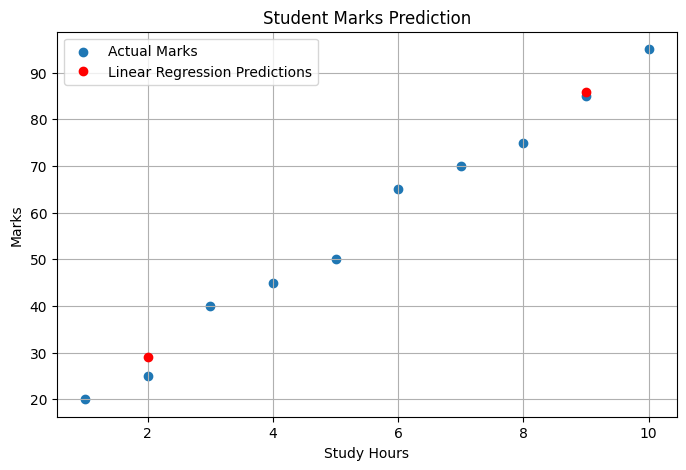

In [14]:

# Plot the original student data
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Study_Hours"],
    df["Marks"],
    label="Actual Marks"
)

plt.plot(
    X_test["Study_Hours"],
    y_pred,
    "ro",
    label="Linear Regression Predictions"
)

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Student Marks Prediction")
plt.legend()
plt.grid(True)

plt.savefig("Student_Marks_Graph.png")
plt.show()
